<a href="https://colab.research.google.com/github/Darshan-12345/Deep-Learning-/blob/main/Assignments/Assignment-02/DL_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Design and implement a Multilayer Perceptron (MLP) for classification of the Iris or Wine

- dataset, and evaluate its performance using accuracy and a confusion matrix

Epoch [20/100], Loss: 0.3695
Epoch [40/100], Loss: 0.1923
Epoch [60/100], Loss: 0.1063
Epoch [80/100], Loss: 0.0724
Epoch [100/100], Loss: 0.0590

Test Accuracy: 96.67%


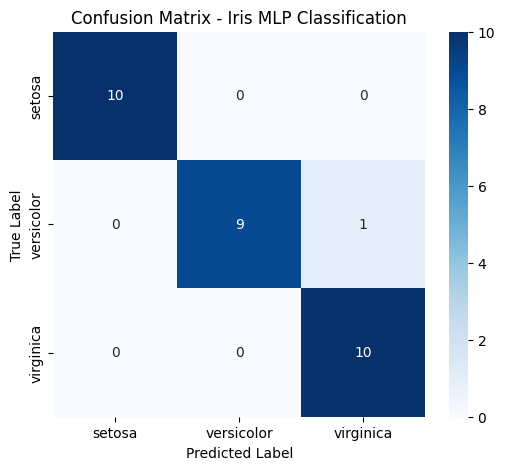

In [1]:
# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and Prepare the Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features (mean=0, variance=1) for stable neural network training
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# 2. Define the Multilayer Perceptron (MLP) Architecture
class IrisMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(IrisMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Initialize hyperparameters
input_dim = X_train.shape[1]   # 4 features
hidden_dim = 16                # Number of neurons in hidden layer
output_dim = len(np.unique(y)) # 3 classes (species)
learning_rate = 0.01
epochs = 100

model = IrisMLP(input_dim, hidden_dim, output_dim)

# Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 3. Train the Model
train_losses = []
for epoch in range(epochs):
    model.train()

    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# 4. Evaluate the Model
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs, 1)

# Compute Accuracy
accuracy = accuracy_score(y_test, predicted.numpy())
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

# Compute Confusion Matrix
cm = confusion_matrix(y_test, predicted.numpy())

# 5. Visualize Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Iris MLP Classification')
plt.show()